SALES DATA ANALYSIS PROJECT

1. Introduction

This project focuses on analyzing sales data using Python.

The main purpose of this project is to understand sales performance, identify business trends, analyze profit, and generate meaningful business insights.

The project follows the complete data analysis workflow:

Data Collection → Data Cleaning → Data Analysis → Data Visualization → Business Insights.

Dataset: Simulated Sales Dataset (2023–2025)

Tools Used: Python, Pandas, NumPy, Matplotlib and Google Colab.

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Display settings
pd.set_option('display.max_columns', None)

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Loading the Dataset

In this section, we load the original sales dataset into Python using Pandas.

In [2]:
from google.colab import files

uploaded = files.upload()

Saving sales_data_raw.csv to sales_data_raw.csv


## 3. Data Understanding

In this section, we explore the dataset structure, number of records, column names, data types, and statistical summary.

In [3]:
# Load the uploaded CSV file

df = pd.read_csv('sales_data_raw.csv')

# Display first five rows
print("First 5 rows:")
display(df.head())

# Dataset shape
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

First 5 rows:


,Order_ID,Order_Date,Customer_ID,Region,State,Category,Sub_Category,Product,Quantity,Unit_Price,Discount,Sales,Profit,Payment_Mode,Customer_Segment
0,ORD-00001,2023-04-14,CUST-0216,Central,Chhattisgarh,Technology,Accessories,Headphones,2,45404.58,0.20,72647.33,2504.47,Cash,Consumer
1,ORD-00002,2025-06-20,CUST-0028,West,Gujarat,Technology,Phones,Cordless Phone,4,41940.27,0.05,159373.03,13136.28,Debit Card,Consumer
2,ORD-00003,2025-11-29,CUST-0228,West,Goa,Office Supplies,Paper,Sticky Notes,1,338.44,0.15,287.67,43.87,UPI,Consumer
3,ORD-00004,2025-11-26,CUST-0023,North,Delhi,Furniture,Storage,Storage Rack,3,13533.34,0.00,40600.02,6151.63,Debit Card,Consumer
4,ORD-00005,2024-04-24,CUST-0030,North,Delhi,Technology,Phones,Smartphone,8,43620.46,0.15,296619.13,4896.64,Credit Card,Corporate


Dataset Shape: (1202, 15)

Column Names:
['Order_ID', 'Order_Date', 'Customer_ID', 'Region', 'State', 'Category', 'Sub_Category', 'Product', 'Quantity', 'Unit_Price', 'Discount', 'Sales', 'Profit', 'Payment_Mode', 'Customer_Segment']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1202 entries, 0 to 1201
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          1202 non-null   object 
 1   Order_Date        1202 non-null   object 
 2   Customer_ID       1202 non-null   object 
 3   Region            1202 non-null   object 
 4   State             1198 non-null   object 
 5   Category          1202 non-null   object 
 6   Sub_Category      1202 non-null   object 
 7   Product           1202 non-null   object 
 8   Quantity          1202 non-null   int64  
 9   Unit_Price        1202 non-null   float64
 10  Discount          1202 non-null   float64
 11  Sales             120

,Quantity,Unit_Price,Discount,Sales,Profit
count,1202.000000,1202.000000,1202.000000,1202.000000,1202.000000
mean,4.476705,12861.588835,0.067845,53237.392903,6104.503935
std,2.291396,16990.558500,0.061040,83733.111105,10092.835612
min,1.000000,30.930000,0.000000,26.290000,-6314.910000
25%,3.000000,574.775000,0.000000,2078.295000,359.187500
50%,5.000000,5287.005000,0.050000,14683.420000,1579.630000
75%,6.000000,17042.677500,0.100000,66311.362500,7214.835000
max,8.000000,64847.710000,0.200000,507358.560000,71670.540000


## 4. Data Cleaning

Data cleaning is an important step in data analysis. In this project, we identify and remove duplicate records, handle missing values, and convert the date column into the correct format.

In [4]:
# Create a backup of original data
df_raw = df.copy()

# Check duplicate records
print("Duplicate Records:", df.duplicated().sum())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

Duplicate Records: 2

Missing Values:
Order_ID            0
Order_Date          0
Customer_ID         0
Region              0
State               4
Category            0
Sub_Category        0
Product             0
Quantity            0
Unit_Price          0
Discount            0
Sales               0
Profit              0
Payment_Mode        4
Customer_Segment    0
dtype: int64


In [5]:
# Remove duplicate records
df = df.drop_duplicates()

# Fill missing State values using the most common
# State within each Region
df['State'] = df['State'].fillna(
    df.groupby('Region')['State'].transform(
        lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan
    )
)

# Fill any remaining missing State values
df['State'] = df['State'].fillna(df['State'].mode()[0])

# Fill missing Payment_Mode values
df['Payment_Mode'] = df['Payment_Mode'].fillna(
    df['Payment_Mode'].mode()[0]
)

# Convert Order_Date into datetime format
df['Order_Date'] = pd.to_datetime(df['Order_Date'])

print("Data cleaning completed successfully!")

Data cleaning completed successfully!


In [6]:
print("Cleaned Dataset Shape:", df.shape)

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nDuplicate Records After Cleaning:")
print(df.duplicated().sum())

display(df.head())

Cleaned Dataset Shape: (1200, 15)

Missing Values After Cleaning:
Order_ID            0
Order_Date          0
Customer_ID         0
Region              0
State               0
Category            0
Sub_Category        0
Product             0
Quantity            0
Unit_Price          0
Discount            0
Sales               0
Profit              0
Payment_Mode        0
Customer_Segment    0
dtype: int64

Duplicate Records After Cleaning:
0


,Order_ID,Order_Date,Customer_ID,Region,State,Category,Sub_Category,Product,Quantity,Unit_Price,Discount,Sales,Profit,Payment_Mode,Customer_Segment
0,ORD-00001,2023-04-14,CUST-0216,Central,Chhattisgarh,Technology,Accessories,Headphones,2,45404.58,0.20,72647.33,2504.47,Cash,Consumer
1,ORD-00002,2025-06-20,CUST-0028,West,Gujarat,Technology,Phones,Cordless Phone,4,41940.27,0.05,159373.03,13136.28,Debit Card,Consumer
2,ORD-00003,2025-11-29,CUST-0228,West,Goa,Office Supplies,Paper,Sticky Notes,1,338.44,0.15,287.67,43.87,UPI,Consumer
3,ORD-00004,2025-11-26,CUST-0023,North,Delhi,Furniture,Storage,Storage Rack,3,13533.34,0.00,40600.02,6151.63,Debit Card,Consumer
4,ORD-00005,2024-04-24,CUST-0030,North,Delhi,Technology,Phones,Smartphone,8,43620.46,0.15,296619.13,4896.64,Credit Card,Corporate


## 5. Key Performance Indicator (KPI) Analysis

In this section, we calculate important business performance metrics such as total sales, total profit, total orders, and total quantity sold.

In [7]:
# Calculate Key Performance Indicators

total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
total_orders = df['Order_ID'].nunique()
total_quantity = df['Quantity'].sum()

profit_margin = (total_profit / total_sales) * 100

print("TOTAL SALES: ₹", round(total_sales, 2))
print("TOTAL PROFIT: ₹", round(total_profit, 2))
print("TOTAL ORDERS:", total_orders)
print("TOTAL QUANTITY SOLD:", total_quantity)
print("PROFIT MARGIN:", round(profit_margin, 2), "%")

TOTAL SALES: ₹ 63885689.89
TOTAL PROFIT: ₹ 7319117.26
TOTAL ORDERS: 1200
TOTAL QUANTITY SOLD: 5371
PROFIT MARGIN: 11.46 %


The KPI analysis shows that the business generated total sales of approximately ₹6.39 crore and total profit of approximately ₹73.19 lakh. The overall profit margin was approximately 11.46%.

## 6. Category-wise Sales and Profit Analysis

In [8]:
# Analyze sales by product category

category_analysis = df.groupby('Category').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Quantity': 'sum'
})

print("Category-wise Analysis:")
display(category_analysis)

Category-wise Analysis:


,Sales,Profit,Quantity
Category,,,
Furniture,13113893.82,1919958.96,1552
Office Supplies,881690.40,187901.63,2083
Technology,49890105.67,5211256.67,1736


## 7. Region-wise Sales and Profit Analysis

In this section, sales and profit are analyzed across different geographical regions to identify the highest-performing region.

In [9]:
# Analyze sales by region

region_analysis = df.groupby('Region').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Quantity': 'sum'
})

region_analysis = region_analysis.sort_values(
    by='Sales', ascending=False
)

print("Region-wise Sales Analysis:")
display(region_analysis)

Region-wise Sales Analysis:


,Sales,Profit,Quantity
Region,,,
West,17241793.41,2018408.34,1328
Central,16216303.33,1856111.60,1468
North,15442453.73,1773620.49,1301
South,14985139.42,1670976.83,1274


## 8. Top 10 Products Analysis

In this section, products are ranked based on their total sales to identify the top-performing products.

In [10]:
# Analyze product performance

product_analysis = df.groupby('Product').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Quantity': 'sum'
})

# Get top 10 products by sales
top_10_products = product_analysis.sort_values(
    by='Sales', ascending=False
).head(10)

print("Top 10 Products by Sales:")
display(top_10_products)

Top 10 Products by Sales:


,Sales,Profit,Quantity
Product,,,
Headphones,6712604.85,680045.18,217
Smartphone,6663982.92,677062.59,222
Cordless Phone,6502812.16,685178.94,190
Laptop,5407965.02,521391.26,183
Desktop,5277502.96,621419.63,205
Feature Phone,5266221.72,529050.20,180
Keyboard,5149941.69,511319.62,191
Wireless Mouse,4679015.20,517447.07,193
Monitor,4230059.15,468342.18,155


## 9. Customer Segment Analysis

This section analyzes sales, profit, orders, and quantity across different customer segments.

In [11]:
# Analyze customer segments

segment_analysis = df.groupby('Customer_Segment').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Order_ID': 'nunique',
    'Quantity': 'sum'
})

segment_analysis = segment_analysis.rename(
    columns={'Order_ID': 'Orders'}
)

print("Customer Segment Analysis:")
display(segment_analysis)

Customer Segment Analysis:


,Sales,Profit,Orders,Quantity
Customer_Segment,,,,
Consumer,38832173.47,4414540.17,715,3220
Corporate,18339085.87,2128283.17,307,1389
Small Business,6714430.55,776293.92,178,762


## 10. Payment Mode Analysis

In this section, sales and profit are analyzed based on different payment methods to identify the most preferred payment mode.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

uploaded = files.upload()

Saving sales_data_raw.csv to sales_data_raw.csv


In [6]:
from google.colab import files

uploaded = files.upload()

Saving sales_data_cleaned.csv to sales_data_cleaned.csv


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('sales_data_cleaned.csv')

df['Order_Date'] = pd.to_datetime(df['Order_Date'])

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (1200, 15)


,Order_ID,Order_Date,Customer_ID,Region,State,Category,Sub_Category,Product,Quantity,Unit_Price,Discount,Sales,Profit,Payment_Mode,Customer_Segment
0,ORD-00001,2023-04-14,CUST-0216,Central,Chhattisgarh,Technology,Accessories,Headphones,2,45404.58,0.20,72647.33,2504.47,Cash,Consumer
1,ORD-00002,2025-06-20,CUST-0028,West,Gujarat,Technology,Phones,Cordless Phone,4,41940.27,0.05,159373.03,13136.28,Debit Card,Consumer
2,ORD-00003,2025-11-29,CUST-0228,West,Goa,Office Supplies,Paper,Sticky Notes,1,338.44,0.15,287.67,43.87,UPI,Consumer
3,ORD-00004,2025-11-26,CUST-0023,North,Delhi,Furniture,Storage,Storage Rack,3,13533.34,0.00,40600.02,6151.63,Debit Card,Consumer
4,ORD-00005,2024-04-24,CUST-0030,North,Delhi,Technology,Phones,Smartphone,8,43620.46,0.15,296619.13,4896.64,Credit Card,Corporate


In [8]:
# Analyze sales by payment mode

payment_analysis = df.groupby('Payment_Mode').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Order_ID': 'nunique',
    'Quantity': 'sum'
})

payment_analysis = payment_analysis.rename(
    columns={'Order_ID': 'Orders'}
)

payment_analysis = payment_analysis.sort_values(
    by='Sales', ascending=False
)

print("Payment Mode Analysis:")
display(payment_analysis)

Payment Mode Analysis:


,Sales,Profit,Orders,Quantity
Payment_Mode,,,,
Credit Card,14655849.72,1736549.10,240,1114
UPI,13108613.39,1444232.42,252,1125
Debit Card,12091524.99,1342805.78,237,1054
Cash,12072164.22,1342106.43,229,1061
Net Banking,11957537.57,1453423.53,242,1017


## 11. Monthly Sales Analysis

This section analyzes monthly sales performance over the three-year period from 2023 to 2025.

In [9]:
# Calculate monthly sales

monthly_sales = df.set_index('Order_Date').resample('ME')['Sales'].sum()

print("Monthly Sales Analysis:")
display(monthly_sales)

# Find highest and lowest sales months

print("\nHighest Sales Month:")
print(monthly_sales.idxmax(), round(monthly_sales.max(), 2))

print("\nLowest Sales Month:")
print(monthly_sales.idxmin(), round(monthly_sales.min(), 2))

Monthly Sales Analysis:


,Sales
Order_Date,
2023-01-31,1205750.96
2023-02-28,1643423.83
2023-03-31,2548622.18
2023-04-30,1806608.81
2023-05-31,2601317.75
2023-06-30,2883067.53
2023-07-31,1487407.77
2023-08-31,501481.24
2023-09-30,2383111.65



Highest Sales Month:
2023-06-30 00:00:00 2883067.53

Lowest Sales Month:
2023-08-31 00:00:00 501481.24


## 12. Yearly Sales and Profit Analysis

This section compares annual sales, profit, and quantity sold to understand business performance over time.

In [10]:
# Extract year from order date

df['Year'] = df['Order_Date'].dt.year

# Calculate yearly performance

yearly_analysis = df.groupby('Year').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Quantity': 'sum'
})

print("Yearly Sales and Profit Analysis:")
display(yearly_analysis)

Yearly Sales and Profit Analysis:


,Sales,Profit,Quantity
Year,,,
2023,21589414.42,2496763.97,1769
2024,22508842.78,2564143.46,1816
2025,19787432.69,2258209.83,1786


## 13. Monthly Sales Trend Visualization

A line chart is used to visualize monthly sales trends from 2023 to 2025.

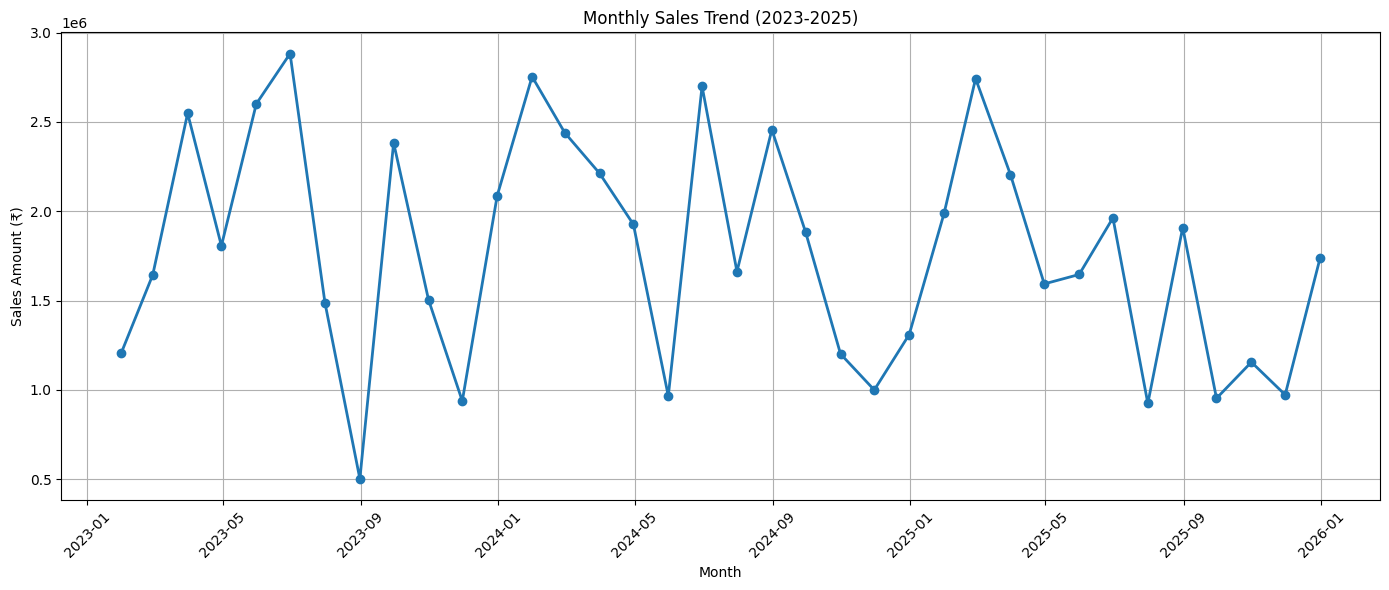

In [11]:
# Plot monthly sales trend

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker='o',
    linewidth=2
)

plt.title('Monthly Sales Trend (2023-2025)')
plt.xlabel('Month')
plt.ylabel('Sales Amount (₹)')

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

## 14. Category-wise Sales Visualization

A bar chart is used to compare sales across different product categories.

In [13]:
# Recreate Category Analysis

category_analysis = df.groupby('Category').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Quantity': 'sum'
})

print("Category-wise Sales and Profit Analysis:")
display(category_analysis)

Category-wise Sales and Profit Analysis:


,Sales,Profit,Quantity
Category,,,
Furniture,13113893.82,1919958.96,1552
Office Supplies,881690.40,187901.63,2083
Technology,49890105.67,5211256.67,1736


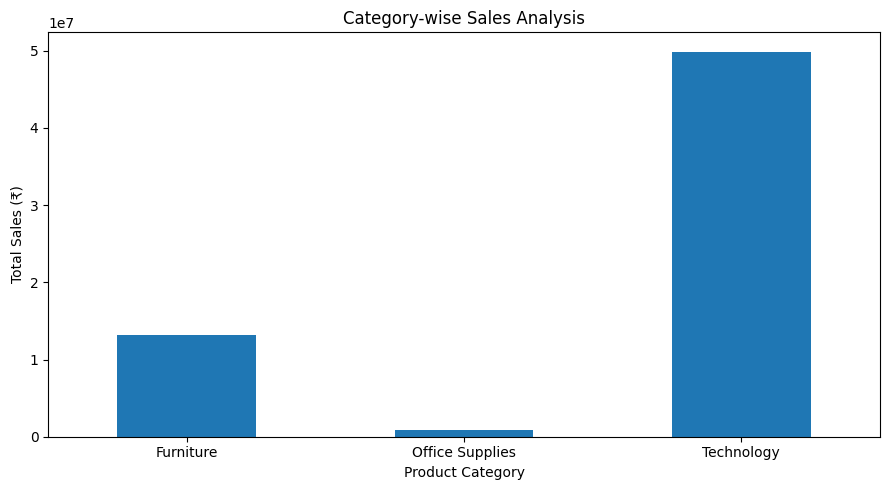

In [14]:
plt.figure(figsize=(9, 5))

category_analysis['Sales'].plot(
    kind='bar',
    title='Category-wise Sales Analysis'
)

plt.xlabel('Product Category')
plt.ylabel('Total Sales (₹)')
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

## 15. Region-wise Sales Visualization

A bar chart is used to compare sales performance across different geographical regions.

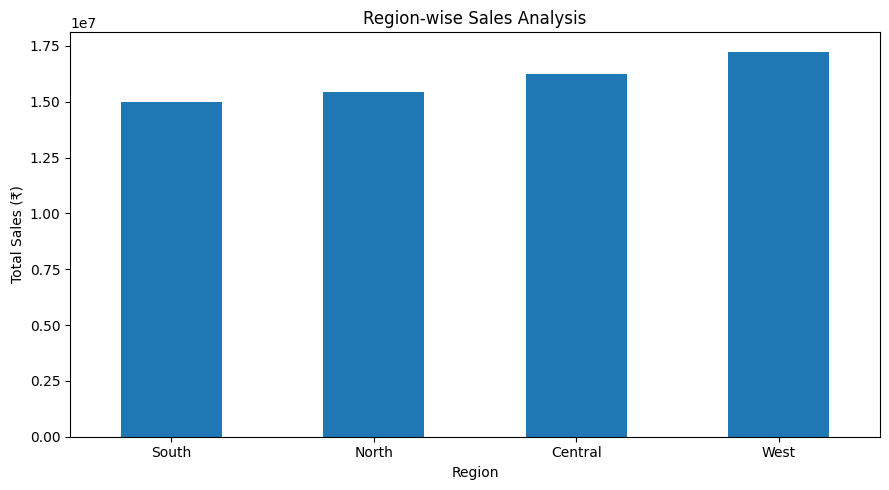

In [16]:
# Recreate region analysis

region_analysis = df.groupby('Region').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Quantity': 'sum'
})

# Plot region-wise sales

plt.figure(figsize=(9, 5))

region_analysis['Sales'].sort_values().plot(
    kind='bar',
    title='Region-wise Sales Analysis'
)

plt.xlabel('Region')
plt.ylabel('Total Sales (₹)')
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

## 16. Top 10 Products Visualization

A horizontal bar chart is used to identify the top 10 products based on total sales.

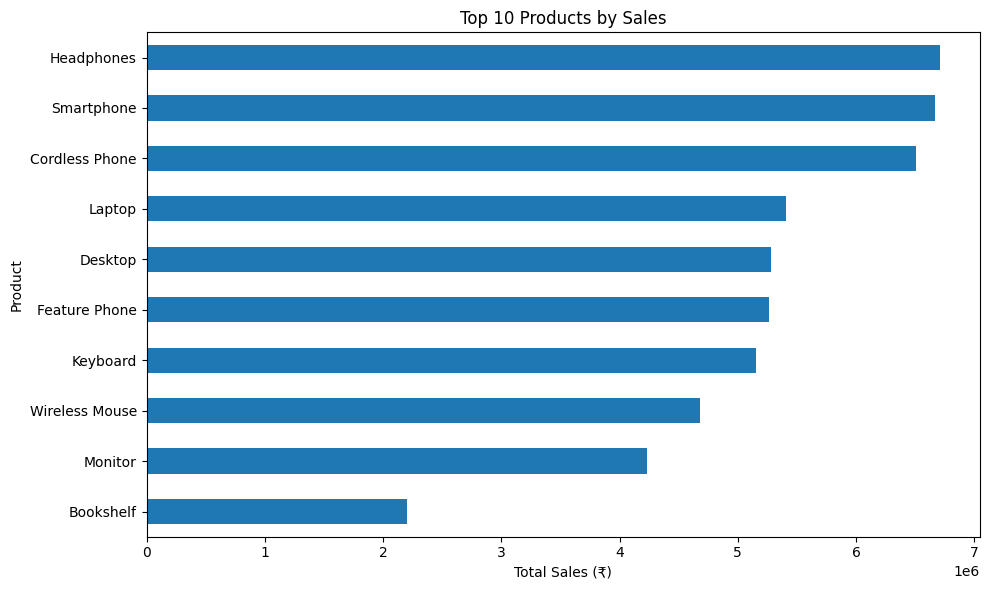

In [17]:
# Recreate product analysis

product_analysis = df.groupby('Product').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Quantity': 'sum'
})

top_10_products = product_analysis.sort_values(
    by='Sales', ascending=False
).head(10)

# Plot top 10 products

plt.figure(figsize=(10, 6))

top_10_products['Sales'].sort_values().plot(
    kind='barh',
    title='Top 10 Products by Sales'
)

plt.xlabel('Total Sales (₹)')
plt.ylabel('Product')
plt.tight_layout()

plt.show()

## 17. Customer Segment Sales Visualization

A pie chart is used to visualize the contribution of different customer segments to total sales.

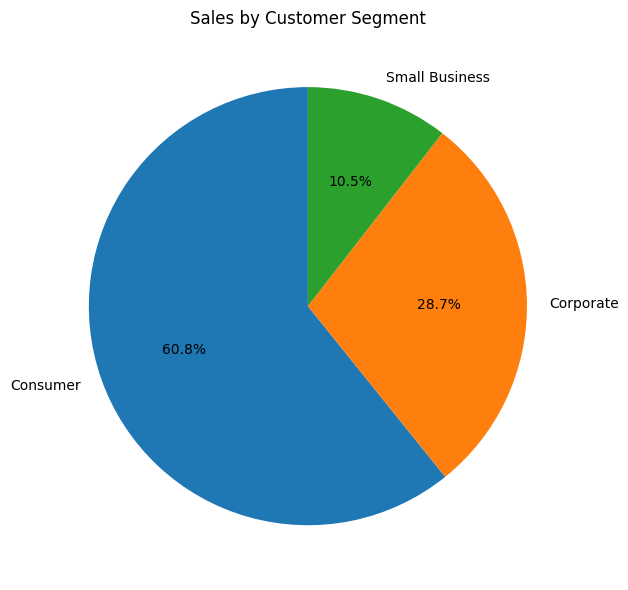

In [18]:
# Recreate customer segment analysis

segment_analysis = df.groupby('Customer_Segment').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Order_ID': 'nunique',
    'Quantity': 'sum'
})

# Plot customer segment sales

plt.figure(figsize=(8, 6))

segment_analysis['Sales'].plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Sales by Customer Segment')
plt.ylabel('')
plt.tight_layout()

plt.show()

## 18. Payment Mode Sales Visualization

A bar chart is used to compare total sales generated through different payment methods.

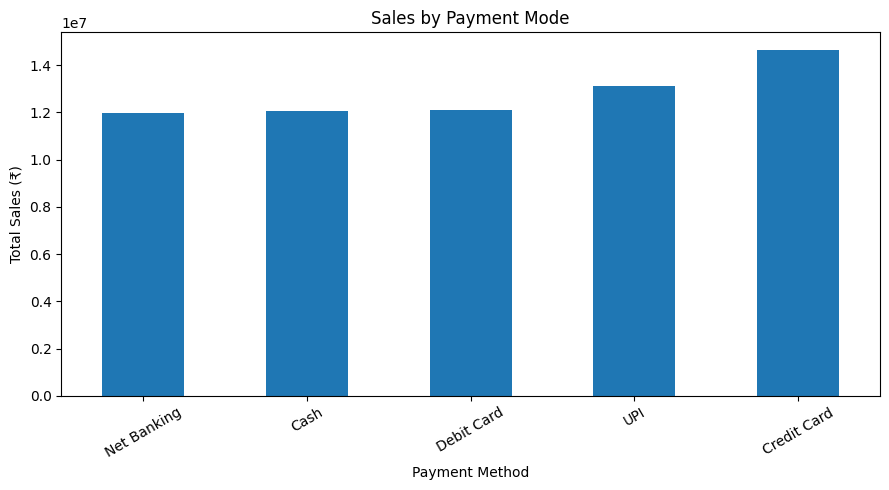

In [19]:
# Recreate payment analysis

payment_analysis = df.groupby('Payment_Mode')['Sales'].sum()

# Plot payment mode sales

plt.figure(figsize=(9, 5))

payment_analysis.sort_values().plot(
    kind='bar',
    title='Sales by Payment Mode'
)

plt.xlabel('Payment Method')
plt.ylabel('Total Sales (₹)')
plt.xticks(rotation=30)
plt.tight_layout()

plt.show()

## 19. Key Business Insights

1. Technology is the highest revenue-generating product category.

2. The West region recorded the highest sales among all regions.

3. Consumer customers contributed approximately 60.79% of total sales.

4. Credit Card was the highest sales-generating payment method.

5. The year 2024 recorded the highest sales and profit.

6. Sales decreased by approximately 12.09% in 2025 compared with 2024.

These insights are based on the simulated sales dataset used for this project.